In [1]:
import os
os.environ["CUDA_VISIBLE_DEVICES"] = "0"
tmp_idx = 12

import torch
import torch.nn.functional as F
import numpy as np
import time
import tqdm

import configargparse
torch.set_default_dtype(torch.float32)

from utils import *
from save_and_plot_utils import *
from opt import *
from model.QTTModel import QTTModel
from model.CPModel import CPModel
from model.VMModel import TensorVM
from model.TTModel import TTModel
from model.TuckerModel import TuckerModel
from robustbench.data import load_cifar10, load_imagenet
from robustbench.utils import clean_accuracy, load_model
import torchattacks
from torchmetrics.functional import peak_signal_noise_ratio as psnr, structural_similarity_index_measure as ssim
from torch.utils.data import DataLoader, TensorDataset
import torchvision.utils as vutils

import wandb

MODEL_CLASSES = {
    'QTT': QTTModel,
    'TT': TTModel,
    'CP': CPModel,
    'Tucker': TuckerModel,
    'VM': TensorVM,
}

import warnings
warnings.filterwarnings("ignore")

def train(target, noisy_target, sampled_indices_all, model, args, attack=False):
    set_seed(args.seed)
    use_wandb = args.use_wandb
    wandb_limited_logging = args.wandb_limited_logging

    if args.device_type == "cpu":
        device = torch.device("cpu")
    else:
        device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    if use_wandb:
        local_dir = "wandb_local"
        #check if wandb_local exists
        if not os.path.exists(local_dir) and not args.only_local_wandb:
            os.makedirs(local_dir)

        if args.only_local_wandb:
            wandb.init(project=f'{args.exp_name}', dir = local_dir, mode='dryrun')
        else:
            wandb.init(project=f'{args.exp_name}')

        num_upsampling_steps = len(args.iterations_for_upsampling)
        args.num_upsampling_steps = num_upsampling_steps
        wandb.config.update(args)  # Log hyperparameters

    # target, noisy_target = get_noisy_data(x_test_adv, args)

    # model = get_TN_model(args, target, noisy_target)

    if args.use_wandb and model.compression_factor is not None:
        wandb.log({"Compression_factor": model.compression_factor})

    grid_size = [args.init_reso for i in range(args.dimensions)]
    iterations = args.num_iterations
    iterations_for_upsampling, iterations_until_next_upsampling = calculate_iterations_until_next_upsampling(args, iterations)

    print("### New grid size {}, Compression Factor {}, Model Size {}, Device {}".format(grid_size, model.compression_factor, model.sz_compressed_gb, args.device_type))

    if args.subset_to_train_on == 1.0:
        sampler = SimpleSamplerImplicit(args.dimensions, batch_size=min(args.max_batch_size, int(model.current_reso**args.dimensions)), max_value=model.current_reso-1)
    else:
        # make a grid with 1s if in sampled_indices and 0s if not
        sampler, procentage_of_sampled_indices = get_subset_sampler(args, sampled_indices_all, model, args.default_val_for_non_sampled, masked_avg_pooling = args.masked_avg_pooling)

    # Initialize optimizer
    if "mlp" in args.model:
        optimizer = torch.optim.Adam(model.get_optparam_groups(lr_init=args.lr, lr_init_mlp=args.lr_init_mlp))
    else:
        optimizer = torch.optim.Adam(model.get_optparam_groups(lr_init=args.lr))

    # Get iterations until next upsampling and use it to determine warmup steps
    if iterations_for_upsampling[0] > iterations:
        iterations_lr_warmup = iterations
    else:
        iterations_lr_warmup = iterations_for_upsampling[0]

    # Scheduler
    lr_gamma = calculate_gamma(args.lr, args.lr_decay_factor_until_next_upsampling, iterations_lr_warmup)
    scheduler = torch.optim.lr_scheduler.ExponentialLR(optimizer, gamma=lr_gamma)
    warmup_steps = args.warmup_steps
    if iterations_for_upsampling[0] > warmup_steps and len(iterations_for_upsampling) > 1:
        warmup_steps = iterations_for_upsampling[0]//2
    lr_warmup_scheduler = linear_warmup_lr_scheduler(optimizer, warmup_steps)

    # Save data while training
    best_recon = None
    best_loss = 1e10
    losses = []
    validation_losses = []
    figsize=(16,8)
    psnr_val = -1
    saved_images = []
    saved_images_iterations = []
    save_times = []
    time_start = time.time()
    psnr_arr = []
    compression_rates = []

    model.to(device)

    loop_obj = tqdm(range(iterations),disable= not args.use_tqdm)
    time_start = time.time()

    # check if paramter rank_upsampling_rank_range and rank_upsampling_iteration_range are set
    # check if contained in args

    if len(args.rank_upsampling_rank_range) > 0 and len(args.rank_upsampling_iteration_range) > 0:
        new_max_ranks, new_rank_upsample_iterations = setup_rank_upsampling(model, args.rank_upsampling_rank_range, args.rank_upsampling_iteration_range)
    else:
        new_max_ranks = []
        new_rank_upsample_iterations = []

    print("New max ranks", new_max_ranks)
    print("New rank upsample iterations", new_rank_upsample_iterations)

    SSIM = []
    PSNR = []
    NRMSE = []
    target_norm = torch.norm(model.target, p='fro').item()
    for ite in loop_obj:

        if ite in iterations_for_upsampling:
            with torch.no_grad():
                ite_index = iterations_for_upsampling.index(ite)
                # save before and after upsampling
                sampler, optimizer, scheduler, best_loss, lr_warmup_scheduler, procentage_of_sampled_indices = upsample_dim(args, model, figsize,
                                                                        saved_images, saved_images_iterations, save_times, time_start, psnr_arr, compression_rates,
                                                                        ite, ite_index, iterations_until_next_upsampling[ite_index], sampled_indices_all = sampled_indices_all)
                if args.use_wandb and model.compression_factor is not None:
                    psnr_val = mse2psnr(loss.item())
                    log_metrics_wandb(ite+1, psnr_val, compression_factor = model.compression_factor)

                # Warmup steps
                warmup_steps = args.warmup_steps
                if ite_index + 1 < len(iterations_until_next_upsampling) and len(iterations_until_next_upsampling) > 1: # max half of iteration between upsampling
                    warmup_steps = (iterations_until_next_upsampling[ite_index]+ iterations_until_next_upsampling[ite_index +1])//2
                warmup_steps = ite + warmup_steps

                grid_size = [model.current_reso for i in range(args.dimensions)]

        if ite in new_rank_upsample_iterations:
            idx = new_rank_upsample_iterations.index(ite)
            model.mask_rank = new_max_ranks[idx]
            model.create_rank_upsampling_mask()

        optimizer.zero_grad()

        batch_indices, batch_indicies_norm = sampler.next_batch()

        loss, reg_term = model(batch_indices.to(device), batch_indicies_norm.to(device))

        if (ite > iterations_for_upsampling[-1]) and (not attack):
            x_rec = model.get_image_reconstruction().detach().to(device)
            # be careful about the einsum
            target = torch.einsum('hwc->chw', model.target).unsqueeze(0).to(device)
            x_rec = torch.einsum('hwc->chw', x_rec).unsqueeze(0)
            minval = x_rec.min()
            maxval = x_rec.max()
            x_rec = (x_rec-minval)/(maxval-minval+1e-8)

            SSIM.append(ssim(target, x_rec).item())
            PSNR.append(psnr(target, x_rec).item())
            nrmse = torch.norm(target-x_rec, p='fro')/target_norm
            NRMSE.append(nrmse.item())

            # resize data before prediction
            if args.data == 'imagenet':
                x_rec = F.interpolate(x_rec, size=(224, 224), mode='bilinear')
            elif args.data == 'cifar10':
                x_rec = F.interpolate(x_rec, size=(32, 32), mode='bilinear')

        reg_term = reg_term * model.regularization_weight

        total_loss = loss + reg_term

        # if model.model == "QTT" and noisy_target is not None and args.noise_std > 0 and args.noise_type is not None:
        #     val_loss = model.get_non_noise_loss(batch_indices.to(device)) # QTT has no get_non_noise_loss()
        #     validation_losses.append(val_loss.item())

        total_loss.backward()
        optimizer.step()
        losses.append(total_loss.item())

        if ite <= warmup_steps:
            lr_warmup_scheduler.step()
        else:
            scheduler.step()

        if ite % args.log_every == 0 or ite-1 in iterations_for_upsampling: # if log_every steps or just after upsampling
            if ite < warmup_steps:
                curr_lr = lr_warmup_scheduler.get_last_lr()[0]
            else:
                curr_lr = scheduler.get_last_lr()[0]

            psnr_val = mse2psnr(loss) # just an idea of global psnr

            loop_obj.set_postfix({"Current LR": curr_lr, "Current reso": model.current_reso, "PSNR": psnr_val})
            if reg_term > 0:
                # set loss and update regularization term
                loop_obj.set_description(f"Loss: {loss}")
                # loop_obj.set_description(f"Loss: {loss}, Reg: {reg_term}")
            else:
                loop_obj.set_description(f"Loss: {loss}")

            # Log metrics to wandb
            if use_wandb and not wandb_limited_logging:
                log_metrics_wandb(ite+1, loss=loss, curr_lr=curr_lr, model=model, grid_size=grid_size, psnr_val=psnr_val)

        # Save data while training
        if ite % args.save_every == 0 or ite in iterations_for_upsampling:
            if args.calculate_psnr_while_training:
                with torch.no_grad():
                    save_data_while_training(args, model, figsize, saved_images, saved_images_iterations, save_times, time_start, psnr_arr, ite)
        if loss.item() < best_loss:
            best_loss = loss.item()
            if reg_term > 0:
                # set loss and update regularization term
                loop_obj.set_description(f"Loss: {loss.item()}")
                #loop_obj.set_description(f"Loss: {loss.item()}, Reg: {reg_term.item()}")
            else:
                loop_obj.set_description(f"Loss: {loss.item()}")

    time_end = time.time()
    print("Training time: " + str(time_end - time_start))
    # log training time
    if use_wandb:
        training_time = time_end - time_start
        log_metrics_wandb(ite+1, training_time=training_time)

    # Take model off GPU for potential memory issues
    model.target = model.target.cpu()
    model.downsampled_target = model.downsampled_target.cpu()

    ### PSNR and reconstruction of object ###
    if model.model == "QTT" and len(model.shape_factors) > 25: # PyTorch cannot permute more than 25 dimensions tensors - have to use batched reconstruction
        if args.noise_std > 0 and args.noise_type is not None or args.subset_to_train_on < 1.0:
            psnr_val, best_recon = model.batched_qtt(compute_reconstruction= args.compute_reconstruction, target = target) #best_recon might be None if
        else:
            psnr_val, best_recon = model.batched_qtt(compute_reconstruction= args.compute_reconstruction) #best_recon might be None if
    else:
        best_recon = model.get_image_reconstruction()
        psnr_val = psnr(model.target, best_recon.detach().cpu())

    print("Best PSNR: " + str(psnr_val))

    save_results(model, figsize, saved_images, saved_images_iterations, save_times, time_start, psnr_arr, ite, best_recon, use_wandb, psnr_val, noisy_target, target, losses, args)

    x_rec = torch.einsum('hwc->chw', best_recon).unsqueeze(0)
    return x_rec, PSNR, SSIM, NRMSE

def get_TN_model(args, target, noisy_target):
    model_args = get_model_args(args, target, noisy_target, args.device_type)
    if args.model in MODEL_CLASSES:
        model = MODEL_CLASSES[args.model]( **model_args)
        if args.model == "VM" and args.dimensions != 3:
            raise NotImplementedError("VM only implemented for 3D")
    else:
        raise NotImplementedError("Model not implemented")

    return model

def get_noisy_data(x_test_adv, args):
    use_wandb = args.use_wandb
    set_seed(args.seed)

    target = x_test_adv.squeeze().detach()
    noisy_target = None
    print("Target shape", target.shape)

    # Noise Experiments
    if args.noise_std > 0 and args.noise_type != "None":
        if noisy_target is None:
            noisy_target = make_noisy_target(target, args)
        else:
            noisy_target = make_noisy_target(noisy_target, args)
    else:
        noisy_target = None

    # Train on Subset
    if args.subset_to_train_on < 1.0:
        print("#### TRAINING ON INCOMPLETE DATA ####")
        # Clone target to noisy_target
        noisy_target = target.clone()

        if args.dimensions == 2:
            all_samples = torch.tensor(np.array(np.meshgrid(np.arange(target.shape[0]), np.arange(target.shape[1])))).T.reshape(-1, 2)
        elif args.dimensions == 3:
            all_samples = torch.tensor(np.array(np.meshgrid(np.arange(target.shape[0]), np.arange(target.shape[1]), np.arange(target.shape[2])))).T.reshape(-1, 3)
        else:
            raise NotImplementedError("Dimensions not implemented")

        num_indices = len(all_samples)
        all_samples = all_samples[torch.randperm(num_indices)]

        if args.is_random_box_impainting :
            # Generate a random square within the image dimensions
            image_height, image_width = target.shape[:2]
            box_samples = int(num_indices * (1 - args.subset_to_train_on))
            square_size = int(np.sqrt(box_samples))
            square_size = min(square_size, target.shape[0], target.shape[1])

            # Random start coordinates for the square
            start_x = np.random.randint(0, target.shape[1] - square_size)
            start_y = np.random.randint(0, target.shape[0] - square_size)

            # Define the square region as the non-sampled indices
            non_sampled_indices_all = [[y, x] for y in range(start_y, start_y + square_size) for x in range(start_x, start_x + square_size)]

            # Convert all_samples and non_sampled_indices_all to set of tuples for set difference operation
            all_samples_set = set(map(tuple, all_samples.tolist()))
            non_sampled_set = set(map(tuple, non_sampled_indices_all))

            # Define the sampled indices as all indices minus the non-sampled indices
            sampled_indices_all = np.array(list(all_samples_set - non_sampled_set))

            # Set the values within the square to the default value for non-sampled data
            for idx in non_sampled_indices_all:
                if args.dimensions == 2:
                    noisy_target[idx[0], idx[1]] = args.default_val_for_non_sampled
                elif args.dimensions == 3:
                    noisy_target[idx[0], idx[1], :] = args.default_val_for_non_sampled

        else:
            sampled_indices_all = all_samples[:int(num_indices * args.subset_to_train_on)]
            non_sampled_indices_all = all_samples[int(num_indices * args.subset_to_train_on):]

            # Set missing data points
            for idx in non_sampled_indices_all:
                if args.dimensions == 2:
                    noisy_target[idx[0], idx[1]] = args.default_val_for_non_sampled
                elif args.dimensions == 3:
                    noisy_target[idx[0], idx[1], :] = args.default_val_for_non_sampled

        if args.plot_subsampled_target:
            plt.imshow(noisy_target)
            plt.axis('off')
            #plt.savefig("noisy_target.png", bbox_inches='tight', pad_inches=0)
            plt.show()


        percentage_of_sampled_indices = len(sampled_indices_all) / len(all_samples)
        print(f"Using {percentage_of_sampled_indices * 100}% of all indices in downsampled target")
    else:
        sampled_indices_all = None

    # Adjust learning rate based on noise/incoplete data
    if noisy_target is not None and args.factor_reduce_lr_based_on_noise != 0:
        lr = args.lr
        if args.subset_to_train_on < 1.0:
            lr = lr * args.factor_reduce_lr_based_on_noise ** (1-args.subset_to_train_on) # lower subset_to_train_on requires lower lr
        elif args.noise_type == "gaussian" or args.noise_type == "laplace":
            lr = lr * args.factor_reduce_lr_based_on_noise ** args.noise_std # more noise requires lower lr
        args.lr = lr
        # update lr in wandb
        if use_wandb:
            wandb.config.update(args,allow_val_change=True)
        print("New Learning Rate: ", args.lr)

    return target, noisy_target, sampled_indices_all

def save_results(model, figsize, saved_images, saved_images_iterations, save_times, time_start, psnr_arr, ite, best_recon, use_wandb, psnr_val, noisy_target, target, losses, args):
    if args.calculate_psnr_while_training: # plot last image - Only for local runs
        with torch.no_grad():
            save_data_while_training(args, model, figsize, saved_images, saved_images_iterations, save_times, time_start, psnr_arr, ite )

    # SSIM
    ssim_val = calculate_ssim(model.target, best_recon, args.payload, args.dimensions, patched = True) # no OOM when patched = True
    print("SSIM: " + str(ssim_val))

    if args.save_learned_recon:
        save_reconstruction(args, best_recon)

    if use_wandb:
        log_metrics_wandb(ite+1, psnr_best=psnr_val, ssim_val=ssim_val)

    # Usage
    if use_wandb and best_recon is not None and args.save_training_images:
        save_image_to_wandb(model, best_recon, ite, save_locally = args.save_images_locally_wandb, PSNR=psnr_val, SSIM=ssim_val)  # Assuming 'ite' is already defined in your code
        # if subset sampling, save noisy target
        if args.subset_to_train_on < 1.0:
            save_image_to_wandb(model, noisy_target, ite, save_locally = args.save_images_locally_wandb, PSNR=psnr_val+10, SSIM=ssim_val)

    if args.save_learned_recon or args.plot_3d_local:
        best_recon_np = None

        if best_recon is not None:
            # Check if best_recon is a PyTorch tensor and if it's on GPU
            if torch.is_tensor(best_recon):
                if best_recon.is_cuda:
                    best_recon_np = best_recon.detach().cpu().numpy()
                else:
                    best_recon_np = best_recon.detach().numpy()
            elif isinstance(best_recon, np.ndarray):
                best_recon_np = best_recon  # best_recon is already a numpy array

        # Check if best_recon_np was successfully created or assigned
        if best_recon_np is not None:
            # Construct the file path
            file_path = f"{args.target}_{args.model}_{args.target}_{args.max_rank}__{args.max_rank}_{args.init_reso}_{args.end_reso}_{args.num_iterations}_{args.seed}.npy"

            # save three slices
            slice_ = int(best_recon_np.shape[0]/2)

            best_slice_axial = best_recon_np[slice_,:,:]
            best_slice_coronal = best_recon_np[:,slice_,:]
            best_slice_sagittal = best_recon_np[:,:,slice_]
            target_slice_axial = target[slice_,:,:]
            target_slice_coronal = target[:,slice_,:]
            target_slice_sagittal = target[:,:,slice_]
            targets = [target_slice_axial, target_slice_coronal, target_slice_sagittal]
            best_slices = [best_slice_axial, best_slice_coronal, best_slice_sagittal]

            if args.save_learned_recon:
                # Save slices as npy file
                np.save(file_path + "_axial", best_slice_axial)
                np.save(file_path + "_coronal", best_slice_coronal)
                np.save(file_path + "_sagittal", best_slice_sagittal)

            if args.plot_3d_local:
                plot3dslices(targets, best_slices, figsize=figsize, title = "Target and Reconstruction", cmap = "gray")


    # Finish wandb run
    if use_wandb:
        wandb.finish()


    if not use_wandb and args.show_end_results_locally:
        gt_list = calculate_and_log_psnr(model, best_recon, noisy_target, use_wandb, args)
        plot_loss_and_saved_images(use_wandb, losses, saved_images, saved_images_iterations, psnr_arr, figsize, save_times, gt_list)
        save_results_locally(args, saved_images, saved_images_iterations, save_times, psnr_arr, gt_list, best_recon, model)
        plot_psnrs(args, psnr_arr, figsize)

def log_gradients(model):
    grad_log = {}
    for name, param in model.named_parameters():
        if param.requires_grad:
                    # Wandb does not accept NoneType, so we check if the gradient is not None
            grad_log[f"grad_{name}"] = wandb.Histogram(param.grad.cpu().numpy()) if param.grad is not None else 0

    wandb.log(grad_log)


def get_subset_sampler(args, sampled_indices_all, model, default_val_for_non_sampled = 0.0, masked_avg_pooling = False):
    if args.payload > 1:
        grid_shape = model.target.shape[:-1]
    else:
        grid_shape = model.target.shape

    sampled_indices_grid = torch.zeros(grid_shape) + default_val_for_non_sampled

    if args.dimensions == 2:
        sampled_indices_grid[sampled_indices_all[:,0], sampled_indices_all[:,1]] = 1
    elif args.dimensions == 3:
        sampled_indices_grid[sampled_indices_all[:,0], sampled_indices_all[:,1], sampled_indices_all[:,2]] = 1
    else:
        raise NotImplementedError("Dimensions not implemented")

    # do average pooling using a factor of model.current_reso to get tiles allowed to be trained on
    factor = int(model.target.shape[0]/model.current_reso)
    sampled_indices_grid = downsample_with_avg_pooling(sampled_indices_grid, factor, args.dimensions, grayscale = True, device = None, masked=masked_avg_pooling)

    # All where sampled_indices_grid is greater equal to default_val_for_non_sampled
    sampled_indices = torch.nonzero(sampled_indices_grid != default_val_for_non_sampled).squeeze() #

    procentage_of_sampled_indices = len(sampled_indices)/len(sampled_indices_grid.view(-1))
    print("Using This Procentage of all indices in downsampled target", procentage_of_sampled_indices) # get sampled_indices proportion to total number of indices

    sampler = SimpleSamplerSubset(args.dimensions, batch_size=min(args.max_batch_size, int(model.current_reso**args.dimensions)), max_value=model.current_reso-1, indices = sampled_indices)
    return sampler, procentage_of_sampled_indices


def log_metrics_wandb(step, psnr_val=None, ssim_val=None, loss=None, curr_lr=None, model=None, training_time=None, grid_size=None, compression_factor=None, psnr_best=None, val_loss=None):
    metrics = {}  # Dictionary to store the metrics to be logged

    # Populate the metrics dictionary based on provided arguments
    if psnr_val is not None:
        metrics["PSNR"] = psnr_val
    if ssim_val is not None:
        metrics["SSIM"] = ssim_val
    if loss is not None:
        metrics["Loss"] = loss.item()
        if grid_size is not None:
            metrics[f"Loss{grid_size[0]}"] = loss.item()
    if curr_lr is not None:
        metrics["Current LR"] = curr_lr
    if model is not None and hasattr(model, 'current_reso'):
        metrics["Current reso"] = model.current_reso
    if training_time is not None:
        metrics["Training_time"] = training_time
    if compression_factor is not None:
        metrics["Compression_factor"] = compression_factor
    if psnr_best is not None:
        metrics["PSNR_best"] = psnr_best

    if val_loss is not None:
        metrics["Val_loss"] = val_loss
    # Log the metrics to wandb
    if metrics:
        try:
            wandb.log(metrics, step=step)
        except:
            print("Could not log to wandb")



@torch.no_grad()
def setup_optimizer(args, model, iteration_index):
    new_lr = args.lr_decay_factor ** (iteration_index + 1) * args.lr

    if "mlp" in args.model.lower():
        new_lr_mlp = args.lr_decay_factor ** (iteration_index + 1) * args.lr_init_mlp
        optimizer = torch.optim.Adam(model.get_optparam_groups(lr_init=new_lr, lr_init_mlp=new_lr_mlp))
    else:
        optimizer = torch.optim.Adam(model.parameters(), lr=new_lr)

    return optimizer, new_lr

def setup_scheduler(optimizer, args, iterations_until_next_upsampling):
    lr_gamma = calculate_gamma(args.lr, args.lr_decay_factor_until_next_upsampling, iterations_until_next_upsampling)
    scheduler = torch.optim.lr_scheduler.ExponentialLR(optimizer, gamma=lr_gamma)
    best_loss = 1e10  # reset best loss

    warmup_steps = args.warmup_steps
    lr_warmup_scheduler = linear_warmup_lr_scheduler(optimizer, warmup_steps)

    return scheduler, best_loss, lr_warmup_scheduler

def setup_sampler(args, sampled_indices_all, model):
    dimensions = model.dimensions

    if args.subset_to_train_on == 1.0:
        sampler = SimpleSamplerImplicit(dimensions, batch_size=min(args.max_batch_size, int(model.current_reso**dimensions)), max_value=model.current_reso-1)
        procentage_of_sampled_indices = None
    else:
        sampler, procentage_of_sampled_indices = get_subset_sampler(args, sampled_indices_all, model, masked_avg_pooling=args.masked_avg_pooling)

    return sampler, procentage_of_sampled_indices

def print_info(model, new_lr, dimensions, new_max_rank):
    if new_max_rank is not None:
        print(f"### New rank {new_max_rank}, lr {new_lr}, new_compression_factor {model.compression_factor}, model_size {model.sz_compressed_gb}")
    else:
        grid_size = [model.current_reso for _ in range(dimensions)]
        print(f"### New grid_size {grid_size}, lr {new_lr}, new_compression_factor {model.compression_factor}, model_size {model.sz_compressed_gb}")


def upsample_dim(args, model, figsize, saved_images, saved_images_iterations, save_times, time_start, psnr_arr, compression_rates, iteration, iteration_index, iterations_until_next_upsampling=1000, sampled_indices_all=None, new_max_rank=None):
    """
    Function that handles both upsample common and upsample dim functionalities.

    Args:
        args: Various arguments needed for the process.
        model: The model being used.
        figsize: Figure size for any plots or images.
        saved_images: A list to store saved images.
        saved_images_iterations: Iterations at which images are saved.
        save_times: A list to store the times at which data is saved.
        time_start: The start time of the process.
        psnr_arr: An array to store PSNR values.
        compression_rates: A list to store compression rates.
        iteration: The current iteration of the process.
        iteration_index: The index of the current iteration.
        iterations_until_next_upsampling: Iterations until the next upsample. Defaults to 1000. # used for lr warmup and scheduler
        sampled_indices_all: All sampled indices. Defaults to None meaning use all. # used for subset sampling
        new_max_rank: The new maximum rank, applicable for rank upsample. Defaults to None.

    Returns:
        A tuple containing the sampler, optimizer, scheduler, best_loss, lr_warmup_scheduler, and percentage_of_sampled_indices.
    """
    model.upsample(iteration_index)

    optimizer, new_lr = setup_optimizer(args, model, iteration_index)
    scheduler, best_loss, lr_warmup_scheduler = setup_scheduler(optimizer, args, iterations_until_next_upsampling)
    sampler, percentage_of_sampled_indices = setup_sampler(args, sampled_indices_all, model)  # Not needed for rank upsample

    print_info(model, new_lr, model.dimensions, None)

    if not should_skip_saving(model, args):
        save_data_while_training(args, model, figsize, saved_images, saved_images_iterations, save_times, time_start, psnr_arr, iteration)

    compression_rates.append(model.compression_factor)

    return sampler, optimizer, scheduler, best_loss, lr_warmup_scheduler, percentage_of_sampled_indices

os.environ['KMP_DUPLICATE_LIB_OK']='True'

parser = configargparse.ArgumentParser(add_help=False)
parser.add_argument('--config', type=str, default='configs/trainadv.yaml', help='Path to the configuration file')
args, unknown = parser.parse_known_args()

config = args.config
args = get_kwargs_dict(config_file=config)

is_valid = check_validity_upsampling_steps(args.init_reso, args.end_reso, args.iterations_for_upsampling, args.num_iterations)
if not is_valid:
    print(" ##### !!!! ##### Invalid upsampling iterations for {} to {} with {} iterations and {} num iterations".format(args.init_reso, args.end_reso, args.iterations_for_upsampling, args.num_iterations))
    raise NotImplementedError("Invalid upsampling iterations")
elif args.noise_type == 'None' and args.noise_std != 0.0 or args.noise_type != 'None' and args.noise_std == 0.0:
    print(" ########## Skipping combination with noise_type: {} and noise_std: {}".format(args.noise_type, args.noise_std))
    raise NotImplementedError("Invalid noise type")
print

if args.device_type == "cpu":
    device = torch.device("cpu")
else:
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

args.device = device

if not os.path.exists(f'adv/{args.data}_{args.end_reso}/{args.model}-{args.attack}/'):
    os.makedirs(f'adv/{args.data}_{args.end_reso}/{args.model}-{args.attack}/')
if not os.path.exists(f'out/{args.data}_{args.end_reso}/{args.model}-{args.attack}/'):
    os.makedirs(f'out/{args.data}_{args.end_reso}/{args.model}-{args.attack}/')
if not os.path.exists(f'viz/{args.data}_{args.end_reso}/{args.model}-{args.attack}/'):
    os.makedirs(f'viz/{args.data}_{args.end_reso}/{args.model}-{args.attack}/')
if not os.path.exists(f'metrics/{args.data}_{args.end_reso}/{args.model}-{args.attack}/'):
    os.makedirs(f'metrics/{args.data}_{args.end_reso}/{args.model}-{args.attack}/')

# x_test, y_test = load_imagenet(n_examples=args.subset_size, data_dir='/home/data-3/Imagenet1K')

x_test = np.load('./CEs_cifar10.npy')
y_test = np.load('./Ys_cifar10.npy')
x_test = torch.tensor(x_test)
y_test = torch.tensor(y_test)

x_test = F.interpolate(x_test, size=(args.end_reso, args.end_reso), mode='bilinear').to(device)
y_test = y_test.to(device)

test_loader = DataLoader(
    torch.utils.data.TensorDataset(x_test, y_test),
    batch_size=1,
    shuffle=False
)

clf = load_model(model_name='Standard', dataset='cifar10', threat_model='Linf').to(device)



x_rec = []
x = []

nrmselist = []
psnrlist = []
ssimlist = []
predlist = []
cln_acc = 0
acc = 0
acc_rec = 0
for i, data in enumerate(test_loader, 0):
    inputs, labels = data
    inputs, labels = inputs.to(device), labels.to(device)

    adv = inputs.squeeze().to(device)
    adv = torch.einsum('chw->hwc', adv).float()

    target, noisy_target, sampled_indices_all = get_noisy_data(adv, args)
    model = get_TN_model(args, target, noisy_target)
    x_rec, PSNR, SSIM, NRMSE = train(target, noisy_target, sampled_indices_all, model, args)

    inputs = F.interpolate(inputs, size=(32,32), mode='bilinear').to(device)
    x_rec = F.interpolate(x_rec, size=(32,32), mode='bilinear').to(device)
    _, preds = torch.max(clf(inputs), 1)
    _, preds_rec = torch.max(clf(x_rec), 1)

    acc += torch.sum(preds == labels).item()
    acc_rec += torch.sum(preds_rec == labels).item()

print("test acc on clean examples (%): {:.2f}".format(
        acc / 512. * 100.0))
print("test acc on FGSM examples (%):  {:.2f}".format(
        acc_rec / 512. * 100.0))







/home/lin/miniforge3/envs/putt/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Upsampling steps are valid.
Target shape torch.Size([256, 256, 3])
#### TRAINING ON INCOMPLETE DATA ####
Using 75.0% of all indices in downsampled target
payload: 3, grid_size: [16, 16, 3], device: cuda:0
Using noisy target
sigma_init 0.4358427714358678
Initialized tn, TensorNetwork([
    Tensor(shape=(3, 4, 12), inds=('payload', 'k0', 'virt0'), tags=oset(['I0']), left_inds=('payload', 'k0')),
    Tensor(shape=(12, 4, 16), inds=('virt0', 'k1', 'virt1'), tags=oset(['I1']), left_inds=('virt0', 'k1')),
    Tensor(shape=(16, 4, 4), inds=('virt1', 'k2', 'virt2'), tags=oset(['I2'])),
    Tensor(shape=(4, 4), inds=('virt2', 'k3'), tags=oset(['I3']), left_inds=('k3',)),
], tensors=4, indices=8)
### New grid size [16, 16], Compression Factor 0.6486486486486487, Model Size 4.410743713378906e-06, Device gpu
Using This Procentage of all indices in downsampled target 1.0
New max ranks []
New rank upsample iterations []
Using noisy target
Using This Procentage of all indices in downsampled target 1.

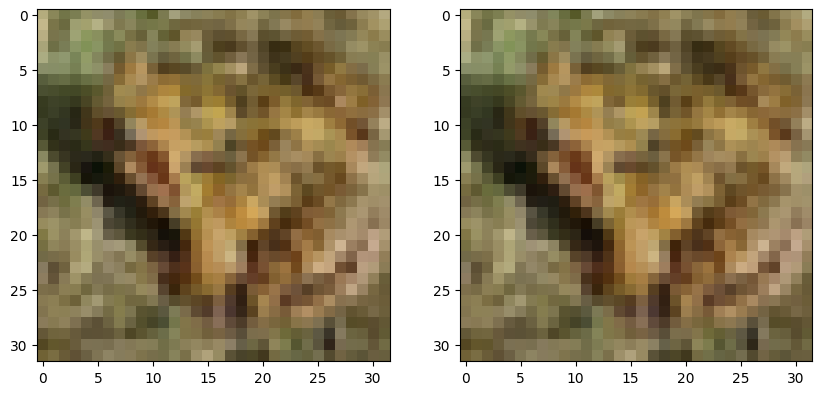

In [3]:
import matplotlib.pyplot as plt

fig, axs = plt.subplots(1, 2, figsize=(10, 5))
x_rec1 = inputs.squeeze().cpu().detach().numpy()
x_rec1 = x_rec1.transpose(1, 2, 0)
x_rec2 = x_rec.squeeze().cpu().detach().numpy()
x_rec2 = x_rec2.transpose(1, 2, 0)


axs[0].imshow(x_rec1)
axs[1].imshow(x_rec2)

plt.show()

In [4]:
x_rec1.min(), x_rec1.max(), x_rec2.min(), x_rec2.max()

(0.013066789, 0.83489203, 0.014282428, 0.8383012)